# ExpTM — continue the recorded 5-epoch run to 10 epochs

Place this notebook beside `02_Train_ExpTM_From_Scratch.ipynb`. Use the **same Python kernel/environment** as the original run. Execute cells in order, once each. The setup checks source/data hashes and restores the local model, optimizer and random states. Original outputs remain unchanged; new checkpoints are written to a new `runs/resume10_*` directory.

Bounded question: do five additional epochs reduce the two observed training-anchor mean-density gaps? Keep the same source, data, learning rate, loss, batch size, sampling seeds and 64 samples per control. Report both endpoint changes, including worsening. This is a descriptive comparison, with no scientific accuracy PASS threshold. Stop at 10 total epochs and this pilot; no full grid is launched.

The checkpoint's zero-based epoch 4 means five completed epochs. The new final checkpoint will be `models/model_9.pt`. RNG loading uses pickle only for your locally generated `rng_4.pt`; do not substitute an untrusted file.


## 1 — Check the environment and original run


In [1]:
from pathlib import Path
import sys, json, hashlib, random, time, uuid, platform, importlib.util
from datetime import datetime, timezone

candidates = [Path.cwd(), Path.cwd()/"ExpTM_Fresh_Training",
              Path.cwd()/"exptm"/"ExpTM_Fresh_Training"]
ROOT = next((p.resolve() for p in candidates if (p/"training_manifest.json").is_file()), None)
assert ROOT is not None, "Open this notebook from the extracted ExpTM_Fresh_Training folder."
missing = [m for m in ["numpy", "torch", "matplotlib", "einops", "yaml"]
           if importlib.util.find_spec(m) is None]
assert not missing, f"Missing packages: {missing}. Select the ExpTM kernel."

import numpy as np
import torch
import matplotlib.pyplot as plt

DEVICE_REQUEST = "cpu"  # Set before creating the model: "auto" or "cpu".
assert DEVICE_REQUEST in {"auto", "cpu"}
if DEVICE_REQUEST == "cpu":
    # Select the CPU default used by the author without modifying author source.
    # CUDA visibility must be configured before torch is imported; use the
    # backbone override in Cell 3 instead.
    pass

manifest = json.loads((ROOT/"training_manifest.json").read_text())
for relative, expected in manifest["sha256"].items():
    assert hashlib.sha256((ROOT/relative).read_bytes()).hexdigest() == expected, relative

SOURCE = ROOT/"author_training_source"
for name, module in list(sys.modules.items()):
    if name == "tm" or name.startswith("tm."):
        filename = getattr(module, "__file__", None)
        assert filename and SOURCE in Path(filename).resolve().parents, (
            "A different tm package is already loaded. Restart this kernel."
        )
sys.path.insert(0, str(SOURCE))
from tm.core.prior import GlobalEquilibriumHarmonicPrior
from tm.core.backbone import ConvBackbone
from tm.core.diffusion_model import DiffusionTrainer, SteeredDiffusionSampler
from tm.core.diffusion_process import VPDiffusion
from tm.architectures.unet_2d_mid_attn import Unet2D
from tm.core.loader import Loader

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Author source:", SOURCE)
print("All bundled file hashes verified.")

PARENT_RUN = ROOT / "runs" / "20261109T222137Z_be6572e7"
PARENT_CHECKPOINT = PARENT_RUN / "models" / "model_4.pt"
PARENT_RNG = PARENT_RUN / "models" / "rng_4.pt"
for path in [PARENT_CHECKPOINT, PARENT_RNG, PARENT_RUN/"config.json",
             PARENT_RUN/"training_history.json", PARENT_RUN/"sample_summary.json"]:
    assert path.is_file(), f"Required original run file is missing: {path}"
parent_config = json.loads((PARENT_RUN/"config.json").read_text())
assert parent_config["device"] == "cpu", "This continuation is prepared for the recorded CPU run."
assert str(torch.__version__) == parent_config["torch_version"], "Select the same PyTorch environment as the original run."
assert np.__version__ == parent_config["numpy_version"], "Select the original NumPy environment."
assert parent_config["source_and_data_sha256"] == manifest["sha256"]
for key, expected in dict(seed=2026110901, epochs=5, batch_size=64,
                          learning_rate=1e-3, diffusion_steps=100,
                          sampling_count=64, sampling_batch=16).items():
    assert parent_config[key] == expected, (key, parent_config[key])
parent_history = json.loads((PARENT_RUN/"training_history.json").read_text())
assert [r["epoch"] for r in parent_history] == [1, 2, 3, 4, 5]
print("Original epoch-5 checkpoint, RNG state and settings found.")


Python: c:\Users\user\AppData\Local\Python\pythoncore-3.14-64\python.exe
PyTorch: 2.14.1+cpu
CUDA available: False
Author source: C:\Users\user\Documents\GitHub\active-matter-reproductions\exptm\ExpTM_Fresh_Training\author_training_source
All bundled file hashes verified.
Original epoch-5 checkpoint, RNG state and settings found.


## 2 — Rebuild the original training arrays


In [2]:
low = np.load(ROOT/"data/LowMuT7.npy", allow_pickle=False)
high = np.load(ROOT/"data/HighMuT7.npy", allow_pickle=False)
assert low.shape == high.shape == (5000, 2, 20, 20)
coords = np.concatenate([low[:, 0], high[:, 0]], axis=0)
assert np.isin(coords, [-1, 1]).all()
n_low, n_high = len(low), len(high)
pressures = np.concatenate([-np.ones(n_low), np.ones(n_high)]).astype(np.float32)
temperatures = np.ones(len(coords), dtype=np.float32)
training_data = np.empty((len(coords), 3, 20, 20), dtype=np.float32)
training_data[:, 0] = coords
training_data[:, 1] = temperatures[:, None, None]
training_data[:, 2] = pressures[:, None, None]
assert np.isfinite(training_data).all()
reference_density = {
    -1.0: (low[:, 0] >= 0).mean(axis=(1, 2)),
     1.0: (high[:, 0] >= 0).mean(axis=(1, 2)),
}
print("Training shape:", training_data.shape)
print("Samples per anchor:", n_low, n_high)
for p, rho in reference_density.items():
    print(f"Supplied training anchor p={p:+.0f}: mean density={rho.mean():.7f}")


Training shape: (10000, 3, 20, 20)
Samples per anchor: 5000 5000
Supplied training anchor p=-1: mean density=0.0481045
Supplied training anchor p=+1: mean density=0.9515275


## 3 — Restore the model and optimizer; prepare a separate output folder


In [3]:
SEED = 2026110901
EPOCHS = 10
START_EPOCH = 5
BATCH_SIZE = 64
SAMPLE_COUNT = 64
SAMPLE_BATCH = 16
torch.set_num_threads(4)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

RUN = ROOT/"runs"/("resume10_"+datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")+"_"+uuid.uuid4().hex[:8])
RUN.mkdir(parents=True, exist_ok=False)
train_loader = Loader(data=training_data, pressures=pressures[:, None],
                      temperatures=temperatures[:, None], control_dims=(1, 3))
assert torch.isfinite(train_loader.data).all()
prior = GlobalEquilibriumHarmonicPrior(shape=train_loader.data.shape,
        channels_info={"coordinate": [0], "fluctuation": [1], "mean": [2]})
model = Unet2D(dim=32, dim_mults=(1, 2, 4), resnet_block_groups=8, channels=3)
backbone = ConvBackbone(model=model, data_shape=train_loader.data_dim,
        target_shape=32, num_dims=4, lr=1e-3, eval_mode="train", self_condition=True)
if DEVICE_REQUEST == "cpu":
    backbone.device = "cpu"
    backbone.model.to("cpu")
diffusion = VPDiffusion(num_diffusion_timesteps=100)

class CheckedTrainer(DiffusionTrainer):
    # Identical loss; only stop rather than updating on a non-finite value.
    def loss_function(self, e, e_pred, weight, loss_type="l2"):
        loss = super().loss_function(e, e_pred, weight, loss_type)
        if not torch.isfinite(loss).all():
            raise FloatingPointError("Non-finite training loss; run stopped.")
        return loss

trainer = CheckedTrainer(diffusion, backbone, train_loader, prior,
                         model_dir=str(RUN/"models"), pred_type="noise")

state = torch.load(PARENT_CHECKPOINT, map_location="cpu", weights_only=True)
assert int(state["epoch"]) == 4
backbone.model.load_state_dict(state["model"], strict=True)
backbone.optim.load_state_dict(state["optim"])
backbone.start_epoch = START_EPOCH
assert backbone.optim.state_dict()["state"], "Optimizer state was not restored."
assert all(g["lr"] == 1e-3 for g in backbone.optim.param_groups)
# This RNG file was written by your own training notebook. It contains NumPy objects.
rng = torch.load(PARENT_RNG, map_location="cpu", weights_only=False)
assert not rng["torch_cuda"], "Unexpected CUDA RNG states in recorded CPU run."
config = dict(parent_config)
config.update(epochs=10, additional_epochs=5, resumed=True,
              parent_run=str(PARENT_RUN), parent_checkpoint=str(PARENT_CHECKPOINT),
              parent_checkpoint_sha256=hashlib.sha256(PARENT_CHECKPOINT.read_bytes()).hexdigest(),
              parent_rng_sha256=hashlib.sha256(PARENT_RNG.read_bytes()).hexdigest(),
              python=sys.version, platform=platform.platform(),
              loader_data_sha256=hashlib.sha256(train_loader.data.numpy().tobytes()).hexdigest(),
              frozen_question="Does five additional epochs reduce both training-anchor mean-density gaps?",
              comparison_rule="Descriptive only: report each gap and its change; no physical accuracy PASS.",
              stopping_rule="Stop after total epoch 10 and the same three 64-sample controls; no automatic grid or further epochs.",
              reproducibility_note="Restore optimizer/RNG and recreate fixed dequantization from original seed; bitwise continuation is not independently certified.")
(RUN/"config.json").write_text(json.dumps(config, indent=2))
TRAINING_STARTED = False
TRAINING_FINISHED = False
print("Model and optimizer restored. No training has started.")
print("Next cell runs epochs 6 to 10 only.")
print("New output directory:", RUN)


C:\Users\user\Documents\GitHub\active-matter-reproductions\exptm\ExpTM_Fresh_Training\author_training_source\tm\core\loader.py:304: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\python_variable_indexing.cpp:362.)
  self.unstd_control = self.data[self.control_slice][self.batch_slice]
C:\Users\user\Documents\GitHub\active-matter-reproductions\exptm\ExpTM_Fresh_Training\author_training_source\tm\core\loader.py:305: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will res

Model and optimizer restored. No training has started.
Next cell runs epochs 6 to 10 only.
New output directory: C:\Users\user\Documents\GitHub\active-matter-reproductions\exptm\ExpTM_Fresh_Training\runs\resume10_20261109T235517Z_058d38a3


## 4 — Train five additional epochs (total 10)


step: 0, loss 0.025
step: 25, loss 0.024
step: 50, loss 0.021
step: 75, loss 0.019
step: 100, loss 0.022
step: 125, loss 0.020
step: 150, loss 0.014
epoch: 5 | train loss: 0.021
Finished 6/10; elapsed 1.9 min; estimated remaining 7.7 min
step: 0, loss 0.020
step: 25, loss 0.019
step: 50, loss 0.027
step: 75, loss 0.020
step: 100, loss 0.014
step: 125, loss 0.019
step: 150, loss 0.018
epoch: 6 | train loss: 0.020
Finished 7/10; elapsed 3.9 min; estimated remaining 5.8 min
step: 0, loss 0.015
step: 25, loss 0.021
step: 50, loss 0.025
step: 75, loss 0.022
step: 100, loss 0.024
step: 125, loss 0.020
step: 150, loss 0.017
epoch: 7 | train loss: 0.018
Finished 8/10; elapsed 5.8 min; estimated remaining 3.9 min
step: 0, loss 0.015
step: 25, loss 0.021
step: 50, loss 0.013
step: 75, loss 0.015
step: 100, loss 0.010
step: 125, loss 0.024
step: 150, loss 0.018
epoch: 8 | train loss: 0.018
Finished 9/10; elapsed 7.8 min; estimated remaining 1.9 min
step: 0, loss 0.016
step: 25, loss 0.021
step: 5

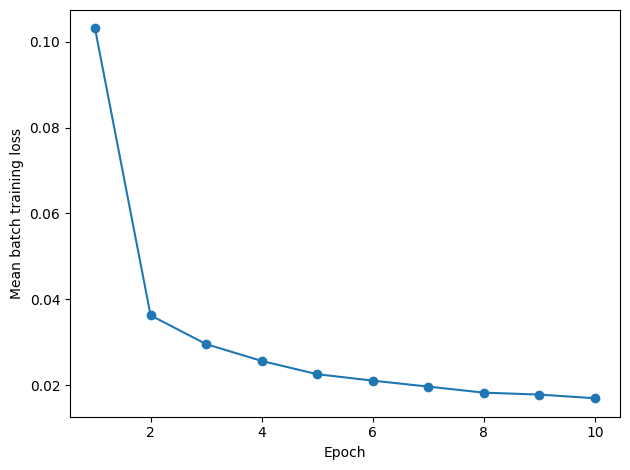

Training finished. Checkpoints are saved in: C:\Users\user\Documents\GitHub\active-matter-reproductions\exptm\ExpTM_Fresh_Training\runs\resume10_20261109T235517Z_058d38a3\models


In [4]:
assert not TRAINING_STARTED, "Training already started in this run. Keep its files; do not rerun this cell."
assert not list((RUN/"models").glob("*.pt")), "Existing checkpoints found."
TRAINING_STARTED = True
history = list(parent_history)
# Restore the saved post-epoch-5 states immediately before training.
random.setstate(rng["python"])
np.random.set_state(rng["numpy"])
torch.set_rng_state(rng["torch_cpu"])
started = time.perf_counter()
try:
    for epoch in range(START_EPOCH, EPOCHS):
        epoch_started = time.perf_counter()
        backbone.start_epoch = epoch
        backbone.model.train()
        trainer.train(1, loss_type="smooth_l1", batch_size=BATCH_SIZE, print_freq=25)
        loss_value = float(trainer.train_losses[-1])
        assert np.isfinite(loss_value)
        checkpoint = RUN/"models"/f"model_{epoch}.pt"
        assert checkpoint.is_file()
        history.append(dict(epoch=epoch+1, mean_batch_loss=loss_value,
                            seconds=time.perf_counter()-epoch_started,
                            checkpoint=checkpoint.name))
        (RUN/"training_history.json").write_text(json.dumps(history, indent=2))
        # Supplement the author's model/optimizer checkpoint with RNG state.
        torch.save(dict(python=random.getstate(), numpy=np.random.get_state(),
                        torch_cpu=torch.get_rng_state(),
                        torch_cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else []),
                   RUN/"models"/f"rng_{epoch}.pt")
        elapsed = time.perf_counter()-started
        remaining = elapsed/(epoch-START_EPOCH+1)*(EPOCHS-epoch-1)
        print(f"Finished {epoch+1}/{EPOCHS}; elapsed {elapsed/60:.1f} min; estimated remaining {remaining/60:.1f} min", flush=True)
    TRAINING_FINISHED = True
    (RUN/"training_status.json").write_text(json.dumps(dict(status="completed",
        epochs_completed=len(history), additional_epochs_completed=len(history)-START_EPOCH, seconds=time.perf_counter()-started,
        scientific_accuracy_validated=False), indent=2))
except BaseException as exc:
    (RUN/"training_status.json").write_text(json.dumps(dict(status="interrupted_or_failed",
        epochs_completed=len(history), error=repr(exc),
        seconds=time.perf_counter()-started), indent=2))
    raise

plt.plot([r["epoch"] for r in history], [r["mean_batch_loss"] for r in history], "o-")
plt.xlabel("Epoch"); plt.ylabel("Mean batch training loss")
plt.tight_layout(); plt.savefig(RUN/"training_loss.png", dpi=150); plt.show()
print("Training finished. Checkpoints are saved in:", RUN/"models")


## 5 — Repeat the original three-control sampling


{"mean_control": -1.0, "variance_control": 1.0, "seed": 2026111001, "n": 64, "density_mean": 0.0, "density_std": 0.0, "seconds": 37.18417199992109, "training_density_mean": 0.048104499999999994, "absolute_mean_density_gap": 0.048104499999999994}
{"mean_control": 0.0, "variance_control": 1.0, "seed": 2026111002, "n": 64, "density_mean": 0.73875, "density_std": 0.07087323805933995, "seconds": 39.5989287000848}
{"mean_control": 1.0, "variance_control": 1.0, "seed": 2026111003, "n": 64, "density_mean": 1.0, "density_std": 0.0, "seconds": 38.08529040007852, "training_density_mean": 0.9515275, "absolute_mean_density_gap": 0.04847250000000003}


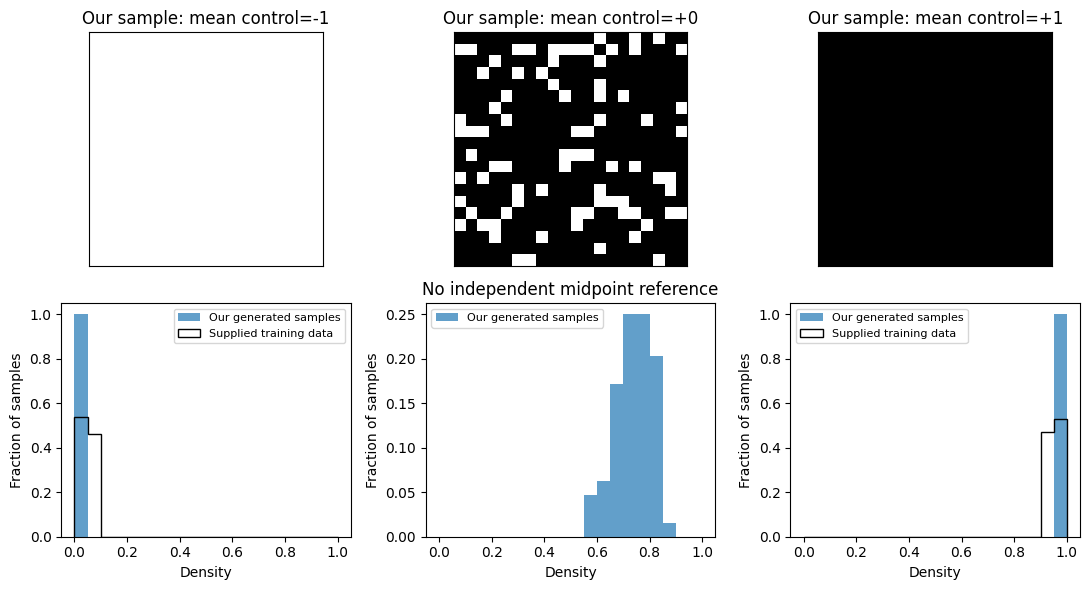

Pilot complete. Results: C:\Users\user\Documents\GitHub\active-matter-reproductions\exptm\ExpTM_Fresh_Training\runs\resume10_20261109T235517Z_058d38a3
This is not the full Figure 2 heatmap or independent physical validation.


In [5]:
assert TRAINING_FINISHED, "Complete Cell 4 first."
assert not (RUN/"sampling_started.json").exists(), "Sampling already started. Preserve this run."
(RUN/"sampling_started.json").write_text(json.dumps({"count_per_control":SAMPLE_COUNT}))
assert SAMPLE_COUNT % SAMPLE_BATCH == 0
backbone.model.eval()
sampler = SteeredDiffusionSampler(diffusion, backbone, train_loader, prior, pred_type="noise")
sample_rows = []
generated = {}
for index, p in enumerate([-1.0, 0.0, 1.0]):
    sample_seed = SEED + 100 + index
    random.seed(sample_seed); np.random.seed(sample_seed); torch.manual_seed(sample_seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(sample_seed)
    t0 = time.perf_counter()
    raw = sampler.sample_loop(num_samples=SAMPLE_COUNT, batch_size=SAMPLE_BATCH,
                              temperature=1.0, pressure=p, gamma=1, eta=1)
    raw = raw.detach().cpu().numpy()
    assert raw.shape == (SAMPLE_COUNT, 3, 20, 20), raw.shape
    assert np.isfinite(raw).all(), "Non-finite generated values; stop."
    np.save(RUN/f"samples_p{p:+.0f}.npy", raw)
    occupancy = (raw[:, 0] >= 0).astype(np.uint8)
    rho = occupancy.mean(axis=(1, 2))
    generated[p] = occupancy
    row = dict(mean_control=p, variance_control=1.0, seed=sample_seed,
               n=len(rho), density_mean=float(rho.mean()),
               density_std=float(rho.std(ddof=1)),
               seconds=time.perf_counter()-t0)
    if p in reference_density:
        row["training_density_mean"] = float(reference_density[p].mean())
        row["absolute_mean_density_gap"] = abs(row["density_mean"]-row["training_density_mean"])
    sample_rows.append(row)
    (RUN/"sample_summary.json").write_text(json.dumps(sample_rows, indent=2))
    print(json.dumps(row), flush=True)

fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for j, p in enumerate([-1.0, 0.0, 1.0]):
    axes[0, j].imshow(generated[p][0], cmap="binary", vmin=0, vmax=1)
    axes[0, j].set_title(f"Our sample: mean control={p:+.0f}")
    axes[0, j].set_xticks([]); axes[0, j].set_yticks([])
    rho = generated[p].mean(axis=(1, 2))
    bins = np.linspace(0, 1, 21)
    axes[1, j].hist(rho, bins=bins, weights=np.ones(len(rho))/len(rho),
                    alpha=.7, label="Our generated samples")
    if p in reference_density:
        ref = reference_density[p]
        axes[1, j].hist(ref, bins=bins, weights=np.ones(len(ref))/len(ref),
                        histtype="step", color="black", label="Supplied training data")
    else:
        axes[1, j].set_title("No independent midpoint reference")
    axes[1, j].set_xlabel("Density"); axes[1, j].set_ylabel("Fraction of samples")
    axes[1, j].legend(fontsize=8)
plt.tight_layout(); plt.savefig(RUN/"pilot_samples.png", dpi=160); plt.show()
print("Pilot complete. Results:", RUN)
print("This is not the full Figure 2 heatmap or independent physical validation.")


## 6 — Compare endpoints and package results


In [6]:

assert TRAINING_FINISHED
old_rows = json.loads((PARENT_RUN/"sample_summary.json").read_text())
new_rows = json.loads((RUN/"sample_summary.json").read_text())
comparison = []
for p in [-1.0, 1.0]:
    old = next(r for r in old_rows if r["mean_control"] == p)
    new = next(r for r in new_rows if r["mean_control"] == p)
    assert old["seed"] == new["seed"] and old["n"] == new["n"] == 64
    target = float(reference_density[p].mean())
    gap5 = abs(old["density_mean"]-target)
    gap10 = abs(new["density_mean"]-target)
    row = dict(mean_control=p, training_mean=target,
               epoch5_mean=old["density_mean"], epoch10_mean=new["density_mean"],
               epoch5_gap=gap5, epoch10_gap=gap10,
               gap_change=gap10-gap5, gap_decreased=gap10<gap5)
    comparison.append(row)
    print(f"p={p:+.0f}: training mean={target:.6f}; "
          f"epoch 5={old['density_mean']:.6f}; epoch 10={new['density_mean']:.6f}; "
          f"gap change={gap10-gap5:+.6f}")
(RUN/"epoch5_vs_epoch10.json").write_text(json.dumps(comparison, indent=2))
print("Negative gap change means improvement in this sample comparison.")
print("This is not a significance test, independent validation, or Figure 2 reproduction.")
print("Keep both outcomes; do not extend training or change seeds based on this result.")
import zipfile
review_files = ["config.json", "training_history.json", "training_status.json",
                "training_loss.png", "pilot_samples.png", "sample_summary.json",
                "epoch5_vs_epoch10.json", "samples_p-1.npy", "samples_p+0.npy", "samples_p+1.npy"]
with zipfile.ZipFile(RUN/"resume10_review.zip", "w", zipfile.ZIP_DEFLATED) as archive:
    for name in review_files:
        archive.write(RUN/name, name)
print("Review package:", RUN/"resume10_review.zip")


p=-1: training mean=0.048104; epoch 5=0.000859; epoch 10=0.000000; gap change=+0.000859
p=+1: training mean=0.951527; epoch 5=0.997773; epoch 10=1.000000; gap change=+0.002227
Negative gap change means improvement in this sample comparison.
This is not a significance test, independent validation, or Figure 2 reproduction.
Keep both outcomes; do not extend training or change seeds based on this result.
Review package: C:\Users\user\Documents\GitHub\active-matter-reproductions\exptm\ExpTM_Fresh_Training\runs\resume10_20261109T235517Z_058d38a3\resume10_review.zip
